# Epocher with Saboo pipeline for run 3
This code takes raw eeg in .fif format and outputs epochs following Saboo's pipeline and estimate for active electrodes using GMM.

This version:  
 -Creates IP for entire high-gamma band (65Hz-115Hz)  
 -Applies correction ratio to IP values from EP24 according to Saboo's self reported 43 timepoints

In [1]:
import mne
import numpy as np
import matplotlib as plt

## 1 Load fif and trigger data

In [ ]:
eeg_path = r"C:\ ... \run3_raw_ieeg.fif"
raw_eeg = mne.io.read_raw_fif(eeg_path, preload=True)

In [3]:
trigger_samples_path = r"C:\ ... \run 3 trigger in samples.txt"
trigger_codes_path = r"C:\ ... \stim_codes_run3_v3.txt"

trigger_samples = []
with open(trigger_samples_path, 'r') as file:
    for line in file:
        trigger_samples.append(float(line.strip()))

trigger_codes = []
with open(trigger_codes_path, 'r') as file:
    for line in file:
        trigger_codes.append(float(line.strip()))

Samples (from edf) number 300 where codes (from csv) number 301. After manual review (see excel "Encoder Dictionnary.xlsx" for details) it is concluded that dropping the first code (a fixation) fixes the issue.

In [4]:
del trigger_codes[0]

Creation of the event object for MNE epoch compatibility

In [5]:
events = np.column_stack([
    np.array(trigger_samples, dtype=np.int_), np.zeros(len(trigger_samples), dtype=np.int_), np.array(trigger_codes, dtype=np.int_)
])

#Remapping all 500 value codes to "Reactive" for simplicity
for i in range(len(events)):
    if events[i, 2] >= 500 and events[i, 2] < 600:
        events[i, 2] = 500

In [6]:
events_ids = {
    "Faces_stat_scr": 111,
    "Faces_stat_neu": 112,
    "Faces_stat_ang": 113,
    "Faces_stat_fea": 114,
    "Faces_stat_hap": 115,
    "Faces_dyn_scr": 121,
    "Faces_dyn_neu": 122,
    "Faces_dyn_ang": 123,
    "Faces_dyn_fea": 124,
    "Faces_dyn_hap": 125,
    "Faces_loc_scr": 131,
    "Faces_loc_mal": 136,
    "Faces_loc_fem": 137,
    "Bodies_stat_scr": 211,
    "Bodies_stat_neu": 212,
    "Bodies_stat_ang": 213,
    "Bodies_stat_fea": 214,
    "Bodies_stat_hap": 215,
    "Bodies_dyn_scr": 221,
    "Bodies_dyn_neu": 222,
    "Bodies_dyn_ang": 223,
    "Bodies_dyn_fea": 224,
    "Bodies_dyn_hap": 225,
    "Bodies_loc_scr": 231,
    "Bodies_loc_mal": 236,
    "Bodies_loc_fem": 237,
    "Objects_stat_scr": 311,
    "Objects_stat_neu": 312,
    "Objects_dyn_scr": 321,
    "Objects_dyn_neu": 322,
    "Houses_stat_scr": 411,
    "Houses_stat_neu": 412,
    "Houses_dyn_scr": 421,
    "Houses_dyn_neu": 422,
    "Houses_loc_scr": 431,
    "Houses_loc_neu": 432,
    "Reactives": 500,
    "Fixations": 600,
}

## 2 Filtering and resampling to 500Hz
Applying IIR notch filter on 50Hz line noise

In [8]:
raw_eeg.notch_filter(freqs=50, method="iir", notch_widths=10)
raw_eeg, events = raw_eeg.resample(500, events=events)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 44 - 56 Hz

IIR filter parameters
---------------------
Butterworth bandstop zero-phase (two-pass forward and reverse) non-causal filter:
- Filter order 16 (effective, after forward-backward)
- Cutoffs at 44.50, 55.50 Hz: -6.02, -6.02 dB



## 3 Creating time windows
[-500ms, 1000ms, +500ms] total of 2000ms  
Stimuli are 1s, fixations are 3.5s on average (all above 2s), different for localizer runs  
No baseline correction performed here, z-scoring on enitre epoch will do the job

In [9]:
epochs = mne.Epochs(raw_eeg, events, event_id=events_ids, tmin=-0.5, tmax=1.5, baseline=None , preload=True, on_missing="ignore")

Not setting metadata
300 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 300 events and 1001 original time points ...
0 bad epochs dropped


Optional code below for manual check of created epochs

In [10]:
epochs

<Epochs | 300 events (all good), -0.5 – 1.5 s (baseline off), ~435.5 MiB, data loaded,
 'Faces_stat_scr': 23
 'Faces_stat_neu': 14
 'Faces_stat_ang': 3
 'Faces_stat_fea': 3
 'Faces_stat_hap': 4
 'Faces_dyn_scr': 0
 'Faces_dyn_neu': 0
 'Faces_dyn_ang': 0
 'Faces_dyn_fea': 0
 'Faces_dyn_hap': 0
 and 28 more events ...>

Not setting metadata
14 matching events found
No baseline correction applied
0 projection items activated


C:\Users\pomoe\AppData\Local\Temp\ipykernel_2608\472023156.py:1: RuntimeWarning: Cannot find channel coordinates in the supplied Evokeds. Not showing channel locations.
  epochs['Faces_stat_neu'].plot_image(picks=["EEG LO8-G2"]);


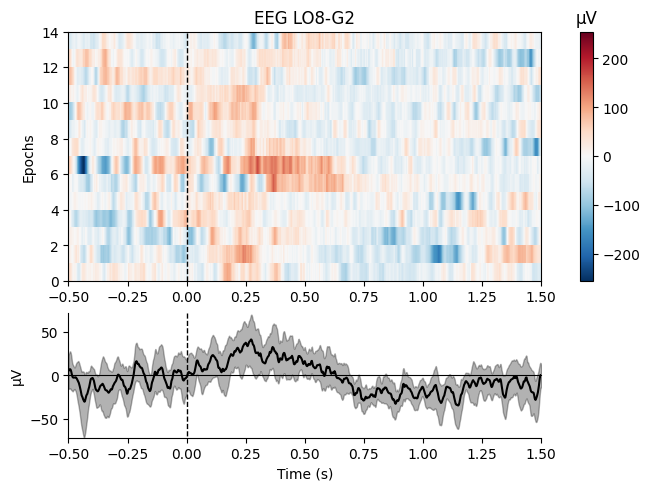

In [11]:
epochs['Faces_stat_neu'].plot_image(picks=["EEG LO8-G2"]);

# 4 Band-pass filtering to 65-115Hz
High-gamma (hg) ranges from 65-115Hz. Using Hann (instead of Barlett-Hanning) because it is the closest available equivalent. Difference is negligible at order 1000.

In [12]:
epochs_hg = epochs.copy().filter(
    l_freq=65, h_freq=115,
    method="fir",
    fir_window="hann",
    filter_length=1000,
    phase="zero"
)

Setting up band-pass filter from 65 - 1.2e+02 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hann window with 0.0546 passband ripple and 44 dB stopband attenuation
- Lower passband edge: 65.00
- Lower transition bandwidth: 16.25 Hz (-6 dB cutoff frequency: 56.88 Hz)
- Upper passband edge: 115.00 Hz
- Upper transition bandwidth: 28.75 Hz (-6 dB cutoff frequency: 129.38 Hz)
- Filter length: 1001 samples (2.002 s)



Optional visualisation

Not setting metadata
14 matching events found
No baseline correction applied
0 projection items activated


C:\Users\pomoe\AppData\Local\Temp\ipykernel_2608\452440296.py:1: RuntimeWarning: Cannot find channel coordinates in the supplied Evokeds. Not showing channel locations.
  epochs_hg['Faces_stat_neu'].plot_image(picks=["EEG LO8-G2"]);


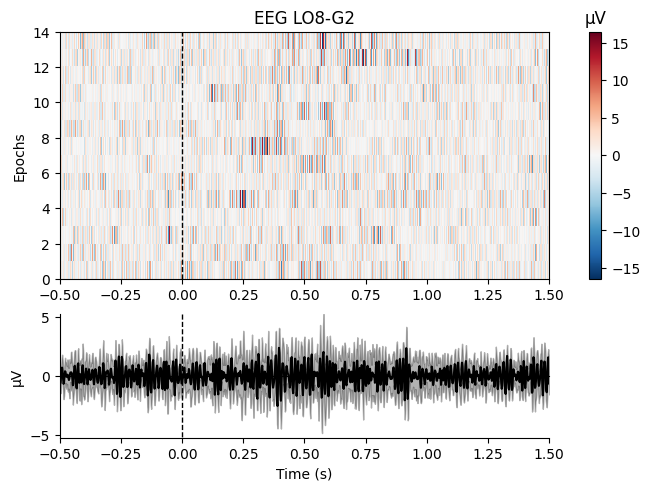

Not setting metadata
150 matching events found
No baseline correction applied
0 projection items activated


C:\Users\pomoe\AppData\Local\Temp\ipykernel_2608\452440296.py:2: RuntimeWarning: Cannot find channel coordinates in the supplied Evokeds. Not showing channel locations.
  epochs_hg['Fixations'].plot_image(picks=["EEG LO8-G2"]);


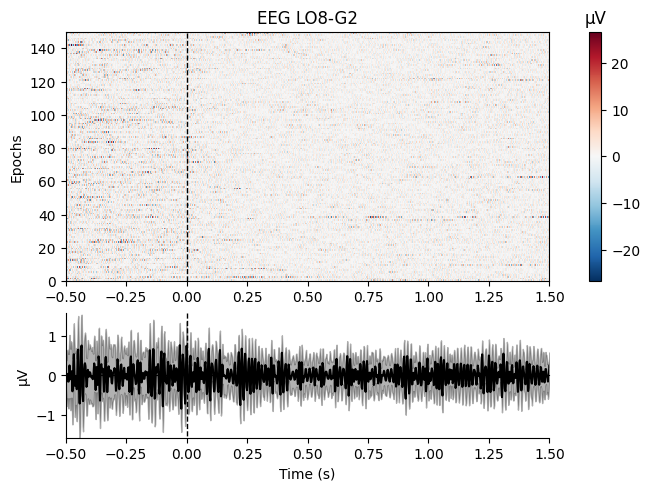

In [13]:
epochs_hg['Faces_stat_neu'].plot_image(picks=["EEG LO8-G2"]);
epochs_hg['Fixations'].plot_image(picks=["EEG LO8-G2"]);

# 5 Spectogram creation
2Hz bins from 65 to 115Hz  
500ms windows (n_cycles = freq * window_length)  
https://mne.tools/stable/generated/mne.Epochs.html#mne.Epochs.compute_tfr

In [14]:
freqs = np.arange(65, 116, 2)

tfr = epochs_hg.compute_tfr(
    method="multitaper",
    freqs=freqs,
    n_cycles=freqs * 0.5,
    time_bandwidth=4,
    return_itc=False,
    average=False
)

Optional visualisation of spectogram

No baseline correction applied


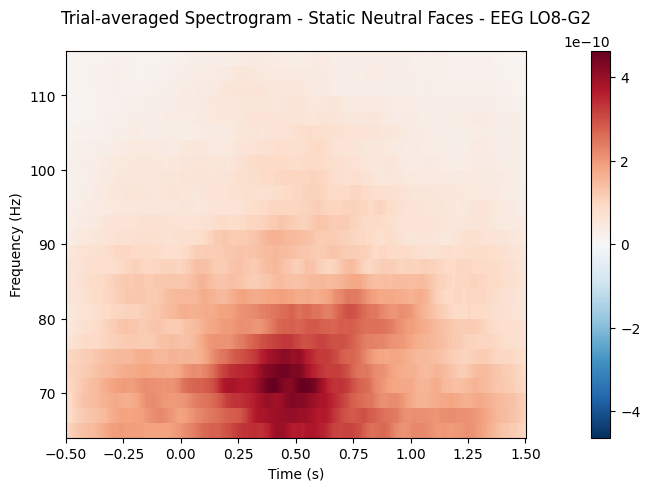

[<Figure size 640x480 with 2 Axes>]

In [15]:
tfr_avg = tfr["Faces_stat_neu"].average()
tfr_avg.plot(
    picks=["EEG LO8-G2"],
    baseline=None,
    mode=None,
    title="Trial-averaged Spectrogram - Static Neutral Faces - EEG LO8-G2"
)

No baseline correction applied


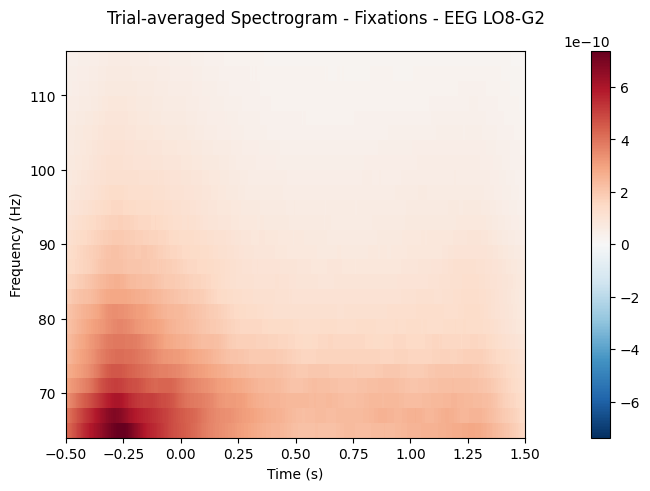

[<Figure size 640x480 with 2 Axes>]

In [16]:
tfr_avg = tfr["Fixations"].average()
tfr_avg.plot(
    picks=["EEG LO8-G2"],
    baseline=None,
    mode=None,
    title="Trial-averaged Spectrogram - Fixations - EEG LO8-G2"
)

# 6 Log normalization of spectograms
Log normalize raw power to flatten dynamic range  
tfr.data has shape (n_epochs, n_channels, n_freqs, n_times)

In [17]:
tfr_log = tfr.copy()
tfr_log.data = np.log(tfr.data)

Optional visualisation of log normalized spectogram

No baseline correction applied


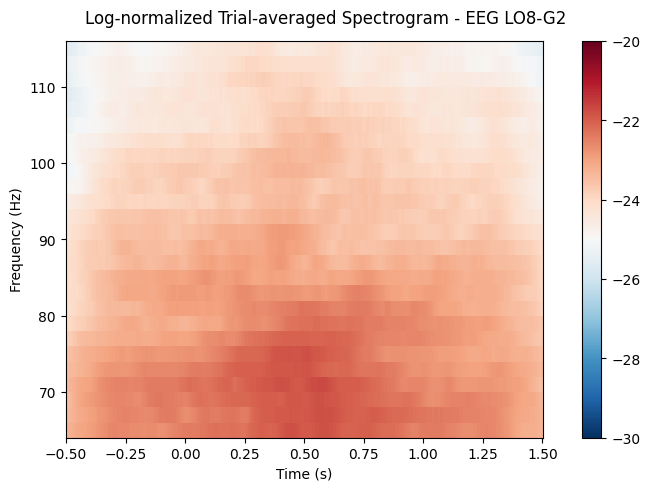

In [18]:
tfr_log_avg = tfr_log["Faces_stat_neu"].average()
tfr_log_avg.plot(
    picks=["EEG LO8-G2"],
    baseline=None,
    mode=None,
    title="Log-normalized Trial-averaged Spectrogram - EEG LO8-G2",
    vlim=(-30, -20),
);

No baseline correction applied


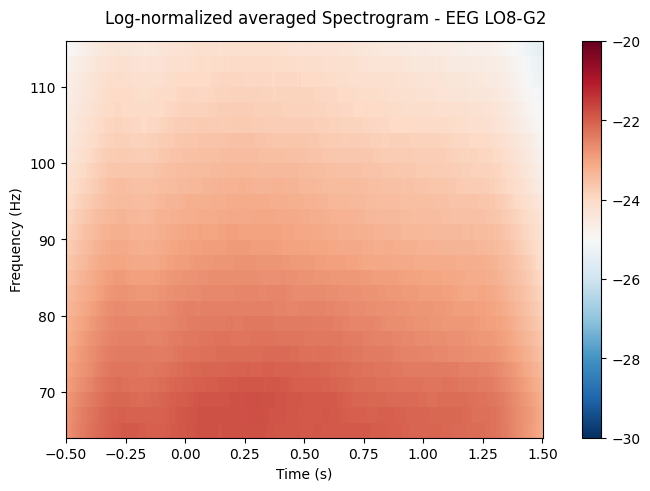

In [19]:
tfr_log_avg = tfr_log.average()
tfr_log_avg.plot(
    picks=["EEG LO8-G2"],
    baseline=None,
    mode=None,
    title="Log-normalized averaged Spectrogram - EEG LO8-G2",
    vlim=(-30, -20),
);

# 7 Z-score normalization of spectograms
Done within each frequency bin using mean and std computed from the entire epoch.  
Mean and std computed from the entire epoch per trial per channel per frequency bin.  
Epochs cropped to [-200ms , 1000ms, +200ms ] for total epoch length of 1400ms (was done to avoid steep drop-offs in mean-band power change)

In [20]:
tfr_zscore = tfr_log.copy()

mean = tfr_log.data.mean(axis=-1, keepdims=True)

In [21]:
std  = tfr_log.data.std(axis=-1, keepdims=True) # advise to take lunch break here

In [22]:
tfr_zscore.data = (tfr_log.data - mean) / std

In [23]:
epochs_hg.crop(tmin=-0.2, tmax=1.2)
tfr_zscore.crop(tmin=-0.2, tmax=1.2)

Data type,Power Estimates
Data source,Epochs
Number of epochs,300
Dims,"epoch, channel, freq, time"
Estimation method,multitaper
Number of channels,190
Number of timepoints,701
Number of frequency bins,26
Frequency range,65.00 – 115.00 Hz


In [24]:
tfr_zscore.shape

(300, 190, 26, 701)

Optional visualisation of Z-score normalized spectograms

No baseline correction applied


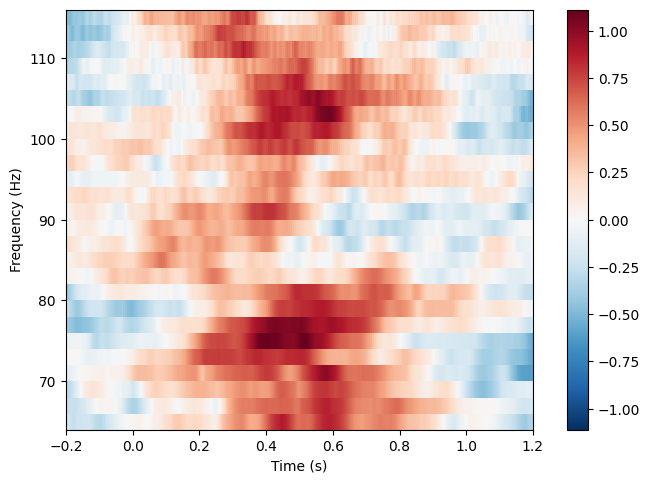

In [25]:
tfr_avg = tfr_zscore["Faces_stat_neu"].average()
tfr_avg.plot(
    picks=["EEG LO8-G2"],
    baseline=None,
    mode=None
);

No baseline correction applied


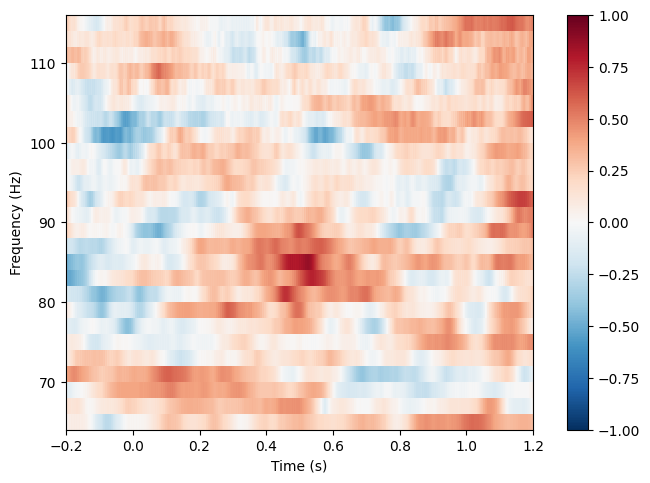

In [26]:
tfr_avg = tfr_zscore["Faces_stat_neu"].average()
tfr_avg.plot(
    picks=["EEG RB8-G2"],
    baseline=None,
    mode=None,
    vlim=(-1,1)
);

# 8 Mean Band Power Change
This simply averages every bin across the frequency axis, leaving only time as variable.

In [27]:
mean_band_power = tfr_zscore.data.mean(axis=-2) # axis=-2 is the frequency axis

In [28]:
mean_band_power.shape

(300, 190, 701)

In [29]:
tfr_zscore_avg_freq = tfr_zscore.copy()
tfr_zscore_avg_freq.data = tfr_zscore.data.mean(axis=-2, keepdims=True) # axis=-2 is the frequency axis

In [30]:
def mean_band_to_evoked(epochs, mean_band_power, condition):
    
    condition_idx = [i for i, event in enumerate(epochs.events[:, 2])
                     if event == epochs.event_id[condition]]
    
    data = mean_band_power[condition_idx].mean(axis=0) 

    evoked = mne.EvokedArray(data, epochs.info, tmin=epochs.times[0],
                             comment=condition)
    return evoked

evoked_faces_stat_neu = mean_band_to_evoked(epochs_hg, mean_band_power, "Faces_stat_neu")

Need more than one channel to make topography for eeg. Disabling interactivity.


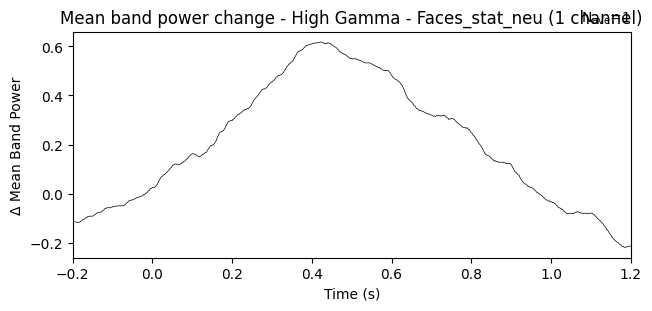

In [31]:
evoked_faces_stat_neu.plot(
    picks=["EEG LO8-G2"], 
    titles={"eeg": "Mean band power change - High Gamma - Faces_stat_neu"}, 
    scalings={"eeg": 1}, 
    units={"eeg": "Δ Mean Band Power"}
);

In [32]:
evoked_faces_stat_neu.copy().pick(["EEG LO8-G2"]).data

array([[-1.12245517e-01, -1.12821137e-01, -1.13689925e-01,
        -1.14812124e-01, -1.15323160e-01, -1.17187960e-01,
        -1.18290832e-01, -1.17377735e-01, -1.16524138e-01,
        -1.14378084e-01, -1.12212055e-01, -1.09208351e-01,
        -1.06784966e-01, -1.05557966e-01, -1.04221029e-01,
        -1.02232451e-01, -9.95826391e-02, -9.81673246e-02,
        -9.64729315e-02, -9.25355905e-02, -9.20496172e-02,
        -9.26896824e-02, -9.07049538e-02, -9.16645090e-02,
        -9.16560030e-02, -9.15765543e-02, -8.99548740e-02,
        -8.69026223e-02, -8.52215539e-02, -8.21172058e-02,
        -7.95844143e-02, -7.81156454e-02, -7.70323741e-02,
        -7.72798914e-02, -7.50962932e-02, -7.52101365e-02,
        -7.41524200e-02, -7.00542947e-02, -6.87929755e-02,
        -6.62082111e-02, -6.14601480e-02, -5.98913696e-02,
        -5.99051072e-02, -5.64791646e-02, -5.70345842e-02,
        -5.77143725e-02, -5.75317650e-02, -5.63265080e-02,
        -5.49147692e-02, -5.58352321e-02, -5.31891608e-0

In [33]:
np.sum(evoked_faces_stat_neu.copy().pick(["EEG RA1-G2"]).data)

np.float64(125.03163983747646)

In [34]:
epochs

<Epochs | 300 events (all good), -0.5 – 1.5 s (baseline off), ~435.5 MiB, data loaded,
 'Faces_stat_scr': 23
 'Faces_stat_neu': 14
 'Faces_stat_ang': 3
 'Faces_stat_fea': 3
 'Faces_stat_hap': 4
 'Faces_dyn_scr': 0
 'Faces_dyn_neu': 0
 'Faces_dyn_ang': 0
 'Faces_dyn_fea': 0
 'Faces_dyn_hap': 0
 and 28 more events ...>

Need more than one channel to make topography for eeg. Disabling interactivity.


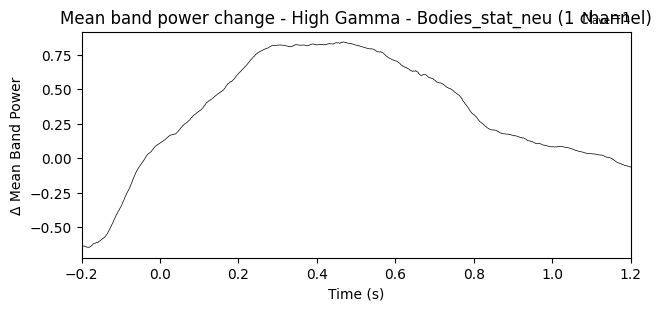

In [35]:
evoked_bodies_stat_neu = mean_band_to_evoked(epochs_hg, mean_band_power, "Bodies_stat_neu")
evoked_bodies_stat_neu.plot(
    picks=["EEG LO8-G2"], 
    titles={"eeg": "Mean band power change - High Gamma - Bodies_stat_neu"}, 
    scalings={"eeg": 1}, 
    units={"eeg": "Δ Mean Band Power"}
);

Need more than one channel to make topography for eeg. Disabling interactivity.


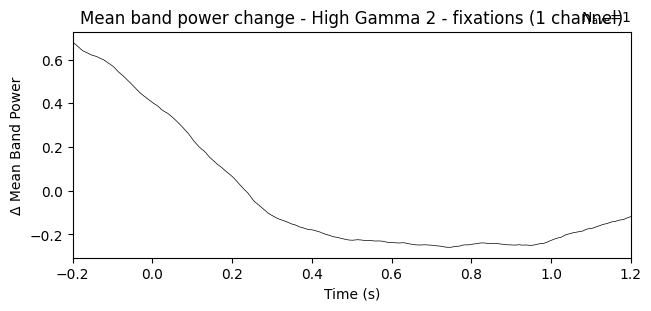

In [36]:
evoked = mean_band_to_evoked(epochs_hg, mean_band_power, "Fixations")
evoked.plot(
    picks=["EEG LO8-G2"], 
    titles={"eeg": "Mean band power change - High Gamma 2 - fixations"}, 
    scalings={"eeg": 1}, 
    units={"eeg": "Δ Mean Band Power"}
);

Need more than one channel to make topography for eeg. Disabling interactivity.


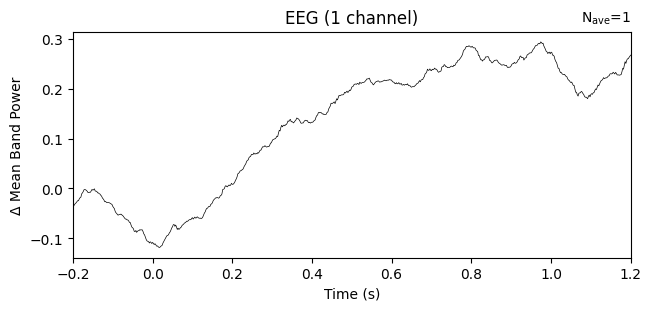

In [37]:
evoked = mean_band_to_evoked(epochs_hg, mean_band_power, "Faces_stat_neu");
evoked.plot(
    picks=["EEG RB1-G2"], 
    scalings={"eeg": 1}, 
    units={"eeg": "Δ Mean Band Power"}
);

In [38]:
evoked.pick(["EEG RB1-G2"]).data

array([[-0.03603467, -0.03526656, -0.03210968, -0.03021344, -0.0286912 ,
        -0.02657693, -0.02440692, -0.02460621, -0.02080165, -0.0184887 ,
        -0.01740729, -0.01082458, -0.00875361, -0.00604637, -0.00241612,
        -0.00198004, -0.00275146, -0.00389695, -0.00565536, -0.0082167 ,
        -0.00828938, -0.00738253, -0.00763023, -0.00493935, -0.00184045,
        -0.00344953, -0.00232254, -0.00069817, -0.00516891, -0.00529585,
        -0.00590119, -0.00867461, -0.00883831, -0.01045384, -0.01118509,
        -0.01363642, -0.01530399, -0.01892165, -0.02083656, -0.02325263,
        -0.02653162, -0.02590045, -0.02770372, -0.02831196, -0.02812957,
        -0.02831551, -0.02882115, -0.03001409, -0.03093739, -0.03179848,
        -0.03562236, -0.03823069, -0.04013397, -0.04548697, -0.04856958,
        -0.04999937, -0.05267191, -0.05333054, -0.05203342, -0.05237052,
        -0.05133328, -0.05178655, -0.05400211, -0.05497725, -0.05728843,
        -0.05954078, -0.06119493, -0.06128174, -0.0

# 9 Induced Power
Simply averaging across time

In [39]:
IP_hg_faces_stat_neu = np.abs(evoked_faces_stat_neu.data).sum(axis=-1)

In [40]:
IP_hg_faces_stat_neu #190 IP values for the 190 contacts

array([164.30162325, 130.18196754, 114.37594331, 122.5686159 ,
       142.37483708, 138.11341912, 135.47150163,  84.90453948,
       112.63953747,  87.3476543 , 109.47912681, 111.72616449,
       102.51166094,  96.43405074, 110.78306932, 115.81199525,
       100.98741302, 122.09047765, 104.1111733 ,  61.78412526,
        52.84066143,  91.77228356,  84.85264359,  82.5767813 ,
        91.86865682, 119.77885418,  89.22747645, 116.58679959,
       105.60731328, 134.38104629,  98.87093041,  91.79696785,
       112.03922417, 165.00233645, 131.50654201,  82.51205978,
       128.61465732, 116.62482826,  67.71303114,  82.47580055,
        83.22913215, 109.10712807, 122.08145145, 105.80980946,
        78.65425151,  88.52034857,  87.48077454,  85.90613823,
       130.14455768,  81.1788298 ,  75.90140703,  76.98162664,
       129.45783222,  65.55424327,  74.9872951 ,  96.18910885,
       127.3934302 , 136.58260524, 124.83499942,  78.2181838 ,
       102.56018195, 109.21882505,  97.46677174,  89.33

# 10 Scaling factor applied on IP values
The scaling factor is based the number of timepoints shared by Saboo through mail (43 at time of summation)

In [41]:
scaling_factor = 43 / len(tfr_zscore.times)

In [42]:
len(tfr_zscore.times)

701

In [43]:
scaling_factor

0.06134094151212553

In [44]:
IP_hg_faces_stat_neu_scaled = IP_hg_faces_stat_neu * scaling_factor

In [45]:
IP_hg_faces_stat_neu_scaled

array([10.07841626,  7.98548446,  7.01592805,  7.5184743 ,  8.73340655,
        8.47200716,  8.30994946,  5.20812439,  6.90941528,  5.35798735,
        6.71555271,  6.85338812,  6.2881618 ,  5.91535547,  6.79553778,
        7.10401683,  6.194663  ,  7.48914485,  6.38627739,  3.78989641,
        3.24129592,  5.62939828,  5.20494105,  5.06533751,  5.6353099 ,
        7.34734769,  5.47329741,  7.15154405,  6.47805203,  8.2430599 ,
        6.06483596,  5.63091244,  6.8725915 , 10.12139867,  8.0667351 ,
        5.06136743,  7.88934417,  7.15387677,  4.15358108,  5.05914326,
        5.10535333,  6.69273396,  7.48859117,  6.49047333,  4.82472584,
        5.42992152,  5.36615307,  5.2695634 ,  7.9831897 ,  4.97958585,
        4.65586377,  4.72212546,  7.94106531,  4.021159  ,  4.59979128,
        5.9003305 ,  7.81443295,  8.3781056 ,  7.6574964 ,  4.79797704,
        6.29113812,  6.69958556,  5.97870354,  5.47965088,  5.87648487,
        5.77569745,  4.39816946, 10.05415952,  8.95895715,  8.52

# 11 Active electrodes form GMM model

In [46]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=2, covariance_type="full")

gmm.means_ = np.array([[0.6358], [2.2780]])
gmm.covariances_ = np.array([[[0.0847**2]], [[2.6996**2]]])
gmm.weights_ = np.array([0.857, 0.1483])
gmm.precisions_cholesky_ = np.linalg.cholesky(np.linalg.inv(gmm.covariances_))

def act_elec_from_model(IPs):
    
    IP_input = IPs.reshape(-1, 1)
    
    post_prob = gmm.predict_proba(IP_input)
    predictions = gmm.predict(IP_input)
    
    active_mask = predictions == 1
    
    print(f"Active electrodes:   {active_mask.sum()}")
    print(f"Inactive electrodes: {(~active_mask).sum()}")
    
    #Print names of active electrodes
    print("\nActive electrodes:")
    for i, ch in enumerate(epochs_hg.ch_names):
        if active_mask[i]:
            print(f"  {ch}  (IP = {IPs[i]:.4f})")

In [47]:
act_elec_from_model(IP_hg_faces_stat_neu_scaled)

Active electrodes:   190
Inactive electrodes: 0

Active electrodes:
  EEG RA1-G2  (IP = 10.0784)
  EEG RA2-G2  (IP = 7.9855)
  EEG RA3-G2  (IP = 7.0159)
  EEG RA4-G2  (IP = 7.5185)
  EEG RA5-G2  (IP = 8.7334)
  EEG RA6-G2  (IP = 8.4720)
  EEG RA7-G2  (IP = 8.3099)
  EEG RA8-G2  (IP = 5.2081)
  EEG RA9-G2  (IP = 6.9094)
  EEG RA10-G2  (IP = 5.3580)
  EEG RA11-G2  (IP = 6.7156)
  EEG RA12-G2  (IP = 6.8534)
  EEG RA13-G2  (IP = 6.2882)
  EEG RA14-G2  (IP = 5.9154)
  EEG RB1-G2  (IP = 6.7955)
  EEG RB2-G2  (IP = 7.1040)
  EEG RB3-G2  (IP = 6.1947)
  EEG RB4-G2  (IP = 7.4891)
  EEG RB5-G2  (IP = 6.3863)
  EEG RB6-G2  (IP = 3.7899)
  EEG RB7-G2  (IP = 3.2413)
  EEG RB8-G2  (IP = 5.6294)
  EEG RB9-G2  (IP = 5.2049)
  EEG RB10-G2  (IP = 5.0653)
  EEG RB11-G2  (IP = 5.6353)
  EEG RB12-G2  (IP = 7.3473)
  EEG RB13-G2  (IP = 5.4733)
  EEG RB14-G2  (IP = 7.1515)
  EEG RC1-G2  (IP = 6.4781)
  EEG RC2-G2  (IP = 8.2431)
  EEG RC3-G2  (IP = 6.0648)
  EEG RC4-G2  (IP = 5.6309)
  EEG RC5-G2  (IP = 6.872